praitraitement d un dataset en ML


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE


In [4]:
df = sns.load_dataset("titanic")


In [5]:

df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [6]:
df.shape


(891, 15)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [8]:
var_num = df.select_dtypes(include=['int64', 'float64']).columns
print("les variables mumeriques")
print(var_num.tolist())

les variables mumeriques
['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']


In [9]:
var_catego = df.select_dtypes(include=['object', 'bool','category']).columns
print("les variables categoriales:")
print(var_catego)

les variables categoriales:
Index(['sex', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town',
       'alive', 'alone'],
      dtype='object')


In [10]:
df.isnull().sum()

,0
survived,0
pclass,0
sex,0
age,177
sibsp,0
parch,0
fare,0
embarked,2
class,0
who,0


In [11]:
(df.isnull().sum() / len(df)) * 100

,0
survived,0.000000
pclass,0.000000
sex,0.000000
age,19.865320
sibsp,0.000000
parch,0.000000
fare,0.000000
embarked,0.224467
class,0.000000
who,0.000000


In [12]:
df = df.drop(columns=['deck'])
x = df.drop(columns=['survived','alive'])
y = df['survived']

In [13]:
x_train, x_test, y_train, y_test = train_test_split(
    x,y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [14]:
print("taille de x_train", x_train.shape)
print("taille de x_test", x_test.shape)
print("taille de y_train", y_train.shape)
print("taille de y_test", y_test.shape)

taille de x_train (712, 12)
taille de x_test (179, 12)
taille de y_train (712,)
taille de y_test (179,)


In [15]:
print(x_train.isnull().sum())

pclass           0
sex              0
age            137
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
embark_town      2
alone            0
dtype: int64


In [16]:
age_med = x_train['age'].median()
embarked_mod = x_train['embarked'].mode()[0]
embark_town_mod = x_train['embark_town'].mode()[0]

In [17]:
x_train['age'] = x_train['age'].fillna(age_med)
x_test['age'] = x_test['age'].fillna(age_med)
x_train['embarked'] = x_train['embarked'].fillna(embarked_mod)
x_test['embarked'] = x_test['embarked'].fillna(embarked_mod)
x_train['embark_town'] = x_train['embark_town'].fillna(embark_town_mod)
x_test['embark_town'] = x_test['embark_town'].fillna(embark_town_mod)

In [18]:
print("")

In [19]:
print(x_train.isnull().sum())
print(x_test.isnull().sum())

pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alone          0
dtype: int64
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alone          0
dtype: int64


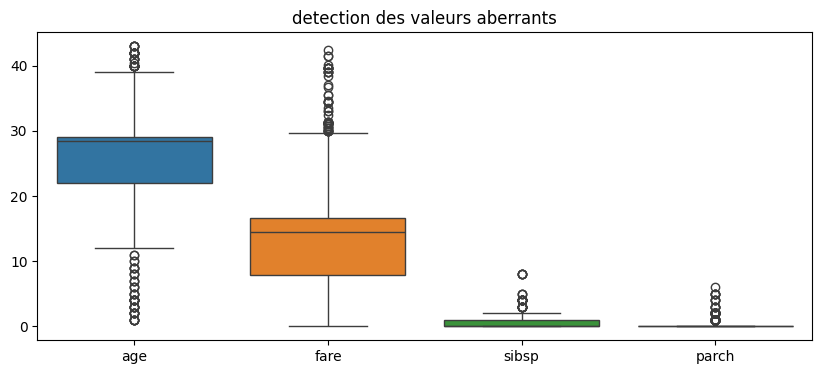

In [45]:
plt.figure(figsize=(10,4))
sns.boxplot(data=x_train[['age', 'fare', 'sibsp', 'parch']])
plt.title("detection des valeurs aberrants")
plt.show()

In [21]:
for colum in ['age', 'fare', 'sibsp', 'parch']:
  Q1 =x_train[colum].quantile(0.25)
  Q3 =x_train[colum].quantile(0.75)
  IQR = Q3 - Q1

  lower = Q1 - 1.5 * IQR
  opper = Q1 + 1.5 * IQR
  print("variable:",colum)
  print("limite inf:",lower)
  print("limite sup:",opper)
  print("")

variable: age
limite inf: 1.0
limite sup: 43.0

variable: fare
limite inf: -26.7605
limite sup: 42.5521

variable: sibsp
limite inf: -1.5
limite sup: 1.5

variable: parch
limite inf: 0.0
limite sup: 0.0



In [22]:
for colum in ['age', 'fare']:
  Q1 =x_train[colum].quantile(0.25)
  Q3 =x_train[colum].quantile(0.75)
  IQR = Q3 - Q1

  lower = Q1 - 1.5 * IQR
  upper = Q1 + 1.5 * IQR
  median =x_train[colum].median()

  x_train.loc[
      (x_train[colum]< lower) | (x_train[colum] > upper),colum
  ] = median

  x_test.loc[
      (x_test[colum] < lower) | (x_test[colum] > upper), colum
  ] = median

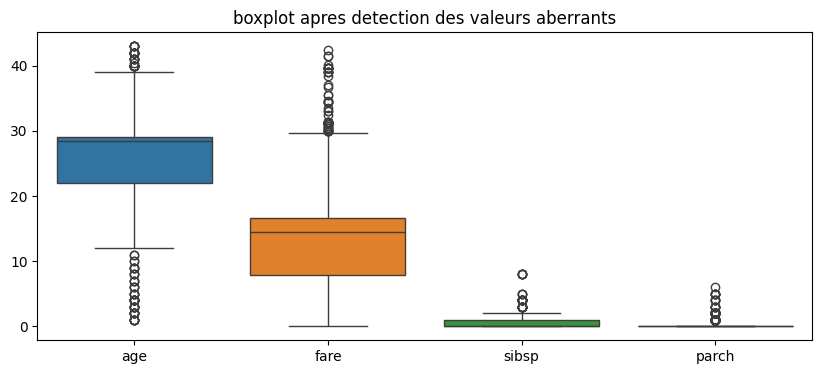

In [46]:
plt.figure(figsize=(10,4))
sns.boxplot(data=x_train[['age', 'fare', 'sibsp', 'parch']])
plt.title("boxplot apres detection des valeurs aberrants")
plt.show()

In [24]:
print(x_train.select_dtypes(include=['object', 'category', 'bool']).columns)

Index(['sex', 'embarked', 'class', 'who', 'adult_male', 'embark_town',
       'alone'],
      dtype='object')


In [25]:
class_mapping = {
    'First': 1,
    'Second': 2,
    'Third': 3,
}
x_train['class'] = x_train['class'].map(class_mapping)
x_test['class'] = x_test['class'].map(class_mapping)
x_train = x_train.drop(columns=['pclass', 'embark_town'])
x_test = x_test.drop(columns=['pclass', 'embark_town'])

In [26]:
print(x_train['class'].value_counts())
print(x_test['class'].value_counts())

class
3    391
1    171
2    150
Name: count, dtype: int64
class
3    100
1     45
2     34
Name: count, dtype: int64


In [27]:
x_train = pd.get_dummies(
    x_train,
    columns=['sex', 'embarked', 'who', 'adult_male', 'alone'],
    drop_first=True,
    dtype=int
)
x_test = pd.get_dummies(
    x_test,
    columns=['sex', 'embarked', 'who', 'adult_male', 'alone'],
    drop_first=True,
    dtype=int
)

In [28]:
print(x_train.shape)
print(x_test.shape)
print(x_train.head())


(712, 12)
(179, 12)
      age  sibsp  parch     fare class  sex_male  embarked_Q  embarked_S  \
692  28.5      0      0  14.4542     3         1           0           1   
481  28.5      0      0   0.0000     2         1           0           1   
527  28.5      0      0  14.4542     1         1           0           1   
855  18.0      0      1   9.3500     3         0           0           1   
801  31.0      1      1  26.2500     2         0           0           1   

     who_man  who_woman  adult_male_True  alone_True  
692        1          0                1           1  
481        1          0                1           1  
527        1          0                1           1  
855        0          1                0           0  
801        0          1                0           0  


In [29]:
num_cols = ['age', 'sibsp', 'parch', 'fare']
print(x_train[num_cols].describe())

              age       sibsp       parch        fare
count  712.000000  712.000000  712.000000  712.000000
mean    26.431882    0.492978    0.390449   14.841485
std      8.350947    1.060720    0.838134    8.462034
min      1.000000    0.000000    0.000000    0.000000
25%     22.000000    0.000000    0.000000    7.895800
50%     28.500000    0.000000    0.000000   14.454200
75%     29.000000    1.000000    0.000000   16.700000
max     43.000000    8.000000    6.000000   42.400000


In [30]:
scal_minmax = MinMaxScaler()
x_train_norm = x_train.copy()
x_test_norm = x_test.copy()
x_train_norm[num_cols] = scal_minmax.fit_transform(
    x_train[num_cols]
)
x_test_norm[num_cols] = scal_minmax.transform(
    x_test[num_cols]
)


In [31]:
print(x_train_norm[num_cols].describe())

              age       sibsp       parch        fare
count  712.000000  712.000000  712.000000  712.000000
mean     0.605521    0.061622    0.065075    0.350035
std      0.198832    0.132590    0.139689    0.199576
min      0.000000    0.000000    0.000000    0.000000
25%      0.500000    0.000000    0.000000    0.186222
50%      0.654762    0.000000    0.000000    0.340901
75%      0.666667    0.125000    0.000000    0.393868
max      1.000000    1.000000    1.000000    1.000000


In [32]:
scal_standar = StandardScaler()
x_train_std = x_train.copy()
x_test_std = x_test.copy()
x_train_std[num_cols] = scal_standar.fit_transform(
    x_train[num_cols]
)
x_test_std[num_cols] = scal_standar.transform(
    x_test[num_cols]
)



In [33]:
print(x_train_std[num_cols].describe())

                age         sibsp         parch          fare
count  7.120000e+02  7.120000e+02  7.120000e+02  7.120000e+02
mean  -2.744372e-17 -5.613487e-18 -1.621674e-17 -1.671572e-16
std    1.000703e+00  1.000703e+00  1.000703e+00  1.000703e+00
min   -3.047530e+00 -4.650843e-01 -4.661832e-01 -1.755124e+00
25%   -5.310772e-01 -4.650843e-01 -4.661832e-01 -8.213827e-01
50%    2.478248e-01 -4.650843e-01 -4.661832e-01 -4.579957e-02
75%    3.077403e-01  4.783345e-01 -4.661832e-01  2.197842e-01
max    1.985375e+00  7.082266e+00  6.697610e+00  3.259014e+00


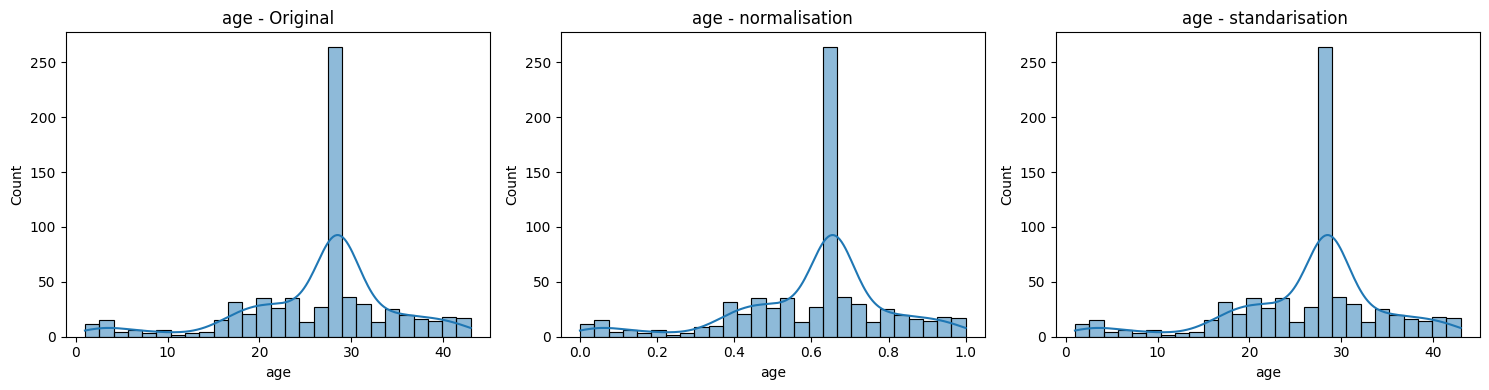

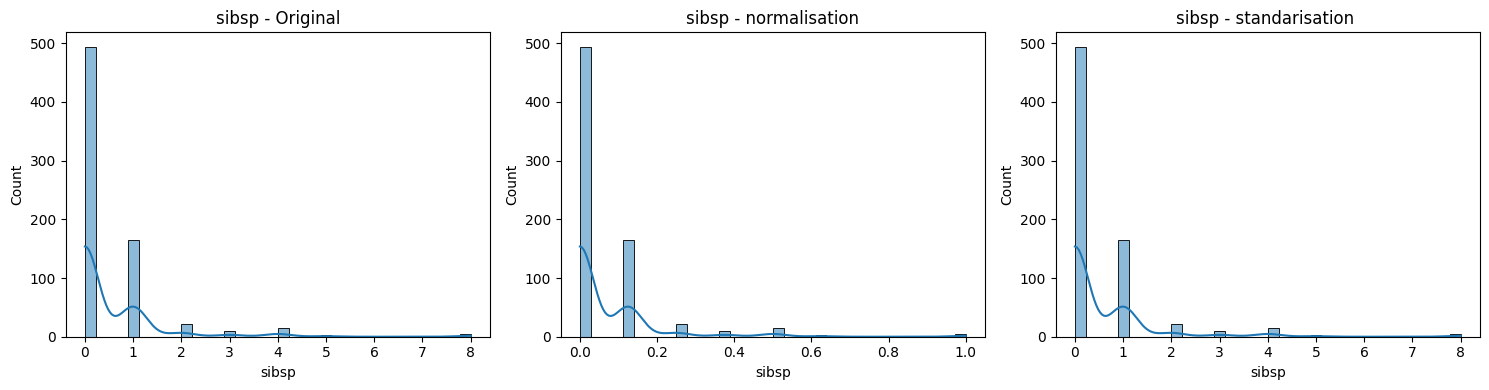

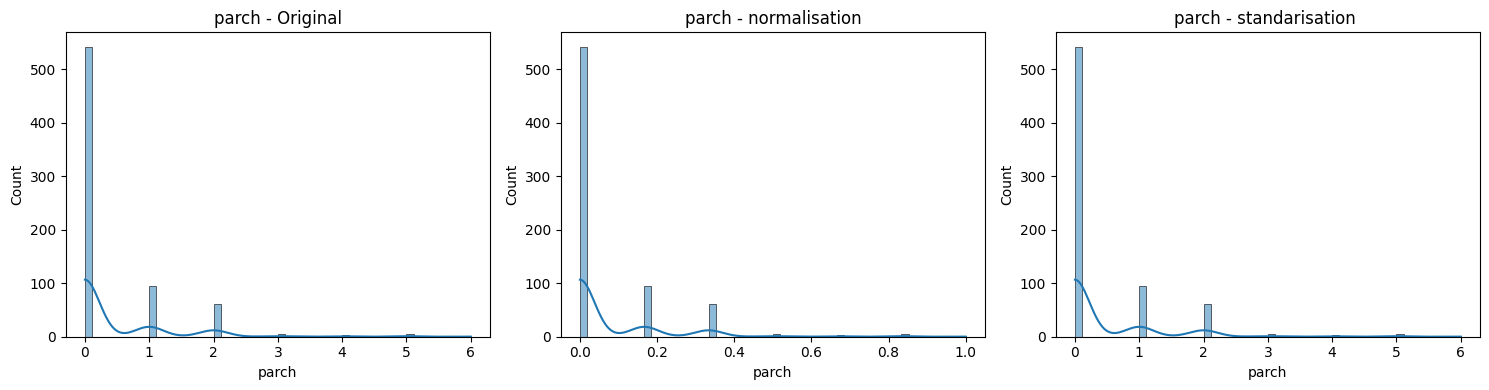

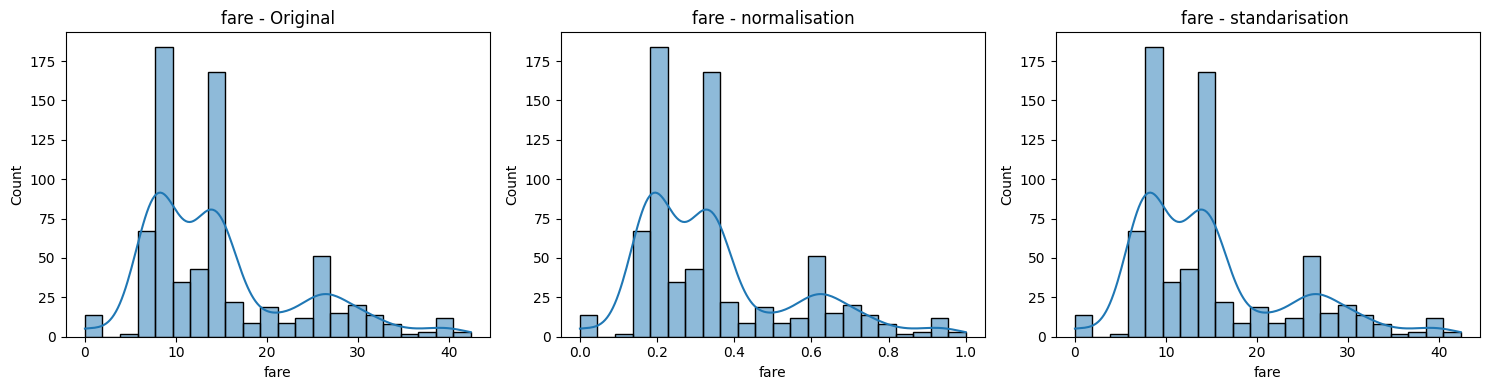

In [34]:
for col in num_cols:

    plt.figure(figsize=(15, 4))

    plt.subplot(1, 3, 1)
    sns.histplot(x_train[col], kde=True)
    plt.title(f'{col} - Original')
    plt.subplot(1, 3, 2)
    sns.histplot(x_train_norm[col], kde=True)
    plt.title(f'{col} - normalisation')
    plt.subplot(1, 3, 3)
    sns.histplot(x_train[col], kde=True)
    plt.title(f'{col} - standarisation ')
    plt.tight_layout()
    plt.show()

In [35]:
print("la distribution de y_train est :")
print(y_train.value_counts())

print("\npourcentage :")
print(y_train.value_counts(normalize=True) * 100)

la distribution de y_train est :
survived
0    439
1    273
Name: count, dtype: int64

pourcentage :
survived
0    61.657303
1    38.342697
Name: proportion, dtype: float64


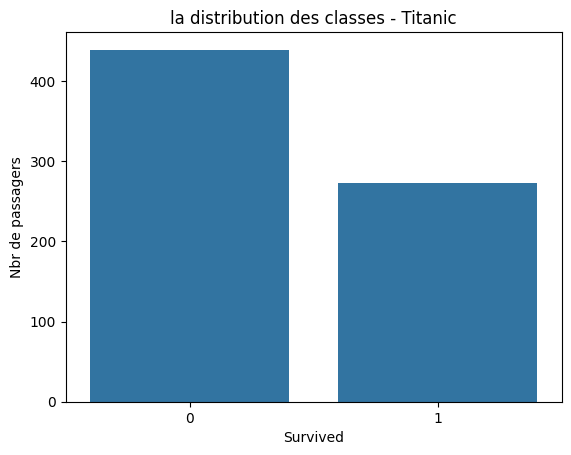

In [36]:
sns.countplot(x=y_train)
plt.title("la distribution des classes - Titanic")
plt.xlabel("Survived")
plt.ylabel("Nbr de passagers")
plt.show()

In [37]:
from imblearn.under_sampling import RandomUnderSampler

udr = RandomUnderSampler(random_state=42)

x_train_udr, y_train_udr = udr.fit_resample(
    x_train_std, y_train
)
print(y_train_udr.value_counts())
print("nouvelle taiille:", x_train_udr.shape)

survived
0    273
1    273
Name: count, dtype: int64
nouvelle taiille: (546, 12)


In [38]:
smote = SMOTE(random_state = 42)

x_train_smote, y_train_smote = smote.fit_resample(
    x_train_std, y_train
)
print(y_train_smote.value_counts())
print("Nouvelle taille :", x_train_smote.shape)

survived
1    439
0    439
Name: count, dtype: int64
Nouvelle taille : (878, 12)


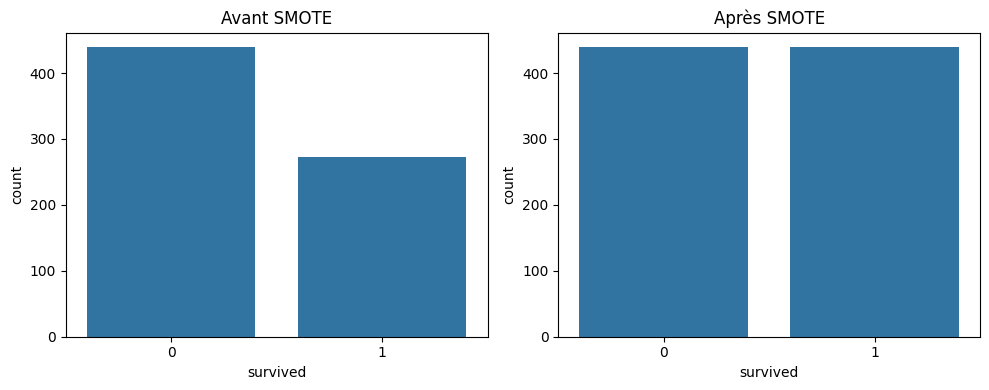

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.countplot(x=y_train, ax=axes[0])
axes[0].set_title("Avant SMOTE")

sns.countplot(x=y_train_smote, ax=axes[1])
axes[1].set_title("Après SMOTE")

plt.tight_layout()
plt.show()

In [40]:
from imblearn.under_sampling import RandomUnderSampler

under = RandomUnderSampler(random_state=42)

x_train_under, y_train_under = under.fit_resample(
    x_train_std, y_train
)

print(y_train_under.value_counts())
print("Nouvelle taille :", x_train_under.shape)

survived
0    273
1    273
Name: count, dtype: int64
Nouvelle taille : (546, 12)


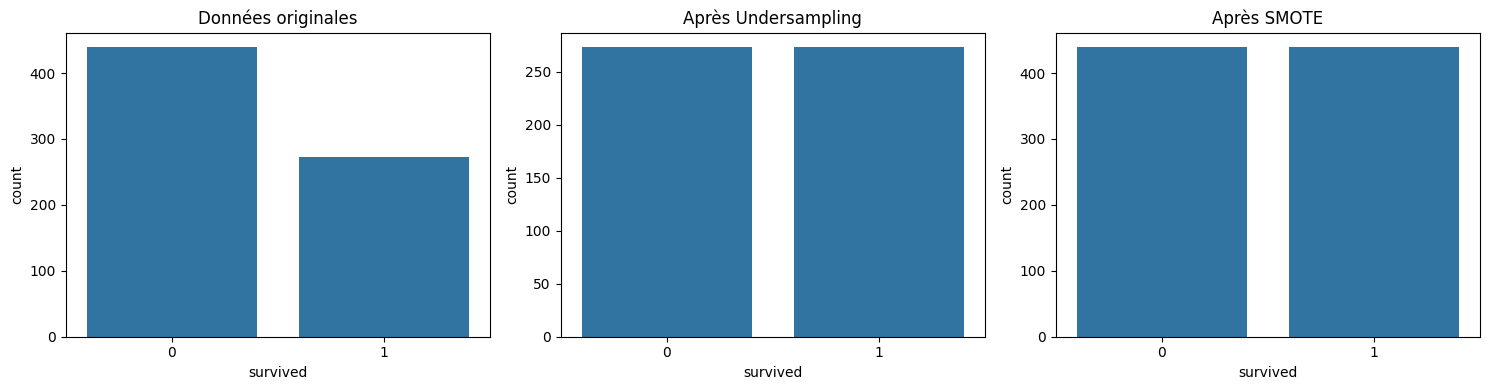

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.countplot(x=y_train, ax=axes[0])
axes[0].set_title("Données originales")

sns.countplot(x=y_train_under, ax=axes[1])
axes[1].set_title("Après Undersampling")

sns.countplot(x=y_train_smote, ax=axes[2])
axes[2].set_title("Après SMOTE")

plt.tight_layout()
plt.show()